In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.interpolate import griddata
from scipy.interpolate import UnivariateSpline

In [2]:
def smooth_spline(x, y, y_std, s_factor=1, k=3):
    """
    Cubic smoothing spline with automatic smoothing chosen so that
    the mean‑squared error roughly equals s_factor × σ².
    If you have y‑errors, pass `w = 1/σ` to UnivariateSpline instead.
    """

    non_zero_idx = np.argwhere(y>0).flatten()
    x = x[non_zero_idx]
    y = y[non_zero_idx]
    y_std = y_std[non_zero_idx]

    # sort, because spline routines need monotonic x
    idx = np.argsort(x)
    y_std = np.maximum(y_std, 1e-10) 

    x = x[idx]
    y = y[idx]
    w = 1/y_std[idx]

    sp = UnivariateSpline(x, y, w=w, k=k, s=s_factor * len(y))

    return sp

In [3]:
ndRlist = [1, 2, 3, 4, 5, 10]
ndlist = [1, 2, 3, 4, 5, 10, 12, 15, 20, 30, 50, 60, 75, 100, 150, 300, 400, 750, 1000, 1500]
nslist = [60000, 30000, 20000, 15000, 12000, 6000, 5000, 4000, 3000, 2000, 1200, 1000, 800, 600, 400, 200, 150, 80, 60, 40]

In [4]:
coeff_list = ["infty", "4", "1"]
files_path1 = [f"../data/gridSearch_NonInt/60000/coeff_{coeff}/max_points_df.csv" for coeff in coeff_list]
files_path2 = [f"../data/gridSearch_int_variable_n_min1/60000/coeff_{coeff}/max_points_df.csv" for coeff in coeff_list]
files_path3 = [f"../data/gridSearch_standard/60000/coeff_{coeff}/max_points_df.csv" for coeff in coeff_list]

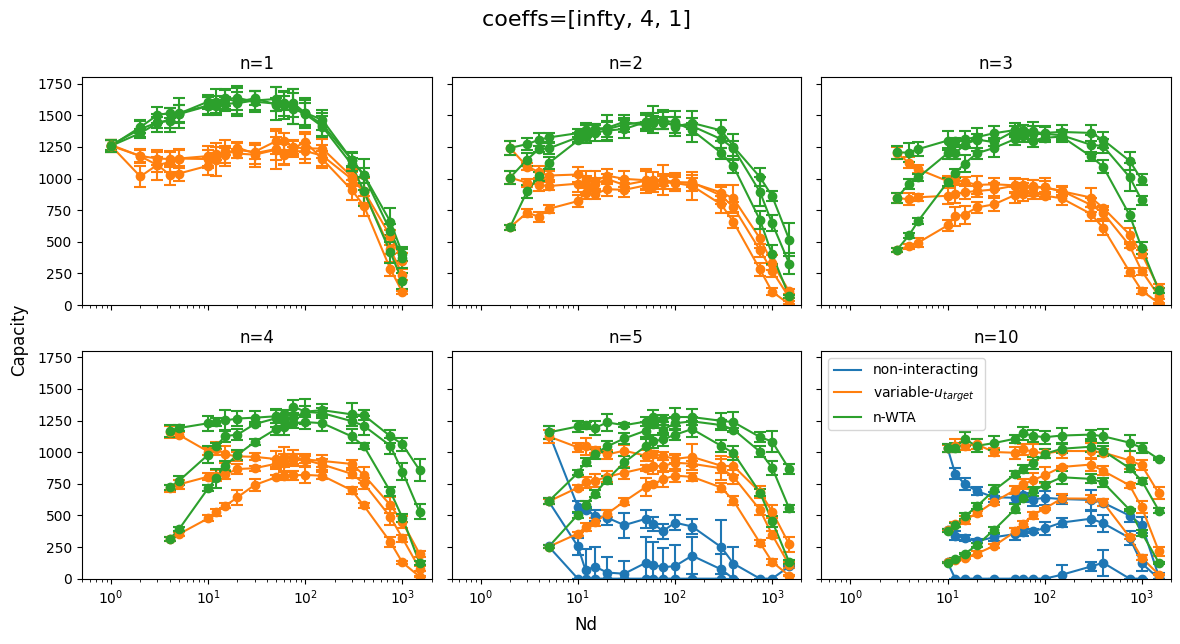

In [5]:
n_panels = len(ndRlist)
n_rows = int(np.floor(np.sqrt(n_panels)))
n_cols = int(np.ceil(n_panels / n_rows))

dfs1 = [pd.read_csv(file_path) for file_path in files_path1]
dfs2 = [pd.read_csv(file_path) for file_path in files_path2]
dfs3 = [pd.read_csv(file_path) for file_path in files_path3]

dfs_list = [dfs1, dfs2, dfs3]

fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, figsize=(12, 6))

for ndR_idx, ndR_value in enumerate(ndRlist):
    ax_i = ndR_idx//n_cols
    ax_j = ndR_idx%n_cols
    for coeff_idx, coeff_str in enumerate(coeff_list):
        for dfs_idx, dfs in enumerate(dfs_list):
            if dfs_idx == 0:
                label_str = "non-interacting"
            elif dfs_idx == 1:
                label_str = r"variable-$u_{target}$"
            else:
                label_str = "n-WTA"
            try:
                df = dfs[coeff_idx]
                subset = df[df['ndR'] == ndR_value]
                subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
                subset = subset.sort_values("nd")
                max_nd = subset['nd'].max()
                min_nd = subset['nd'].min()
                nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
                try:
                    xs = np.log(subset['nd'].to_numpy())
                    ys = subset['capacity'].to_numpy()
                    y_sem = subset['sem'].to_numpy()
                    # spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
                    # fitted_capacity = spline(np.log(nd_plot_list))

                    # ax[ax_i, ax_j].plot(nd_plot_list, fitted_capacity, label=f"{coeff_str}", c=f"C{ndR_idx}")
                    if coeff_idx == 0:
                        ax[ax_i, ax_j].plot(subset['nd'], subset['capacity'], label=f"{label_str}", c=f"C{dfs_idx}")    #  Original points line
                    else:
                        ax[ax_i, ax_j].plot(subset['nd'], subset['capacity'], c=f"C{dfs_idx}")    #  Original points line
                except: pass

                ax[ax_i, ax_j].errorbar(
                    x=subset['nd'],
                    y=subset['capacity'],
                    yerr=2.571*subset['sem'], 
                    fmt='o',  
                    capsize=4,
                    capthick=1.5,
                    elinewidth=1.5, 
                    c=f"C{dfs_idx}"
                )
            except: pass

    ax[ax_i, ax_j].set_xlim(0.5, 2000)
    ax[ax_i, ax_j].set_ylim(0, 1800)
    # ax[ax_i, ax_j].set_xlabel("Nd")
    # ax[ax_i, ax_j].set_ylabel("capacity")
    ax[ax_i, ax_j].set_xscale("log")
    ax[ax_i, ax_j].set_title(f"n={ndR_value}") 
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.supxlabel("Nd")
fig.supylabel("Capacity")
fig.suptitle("coeffs=[infty, 4, 1]", fontsize=16, y=1.05)
ax[1, 2].legend()


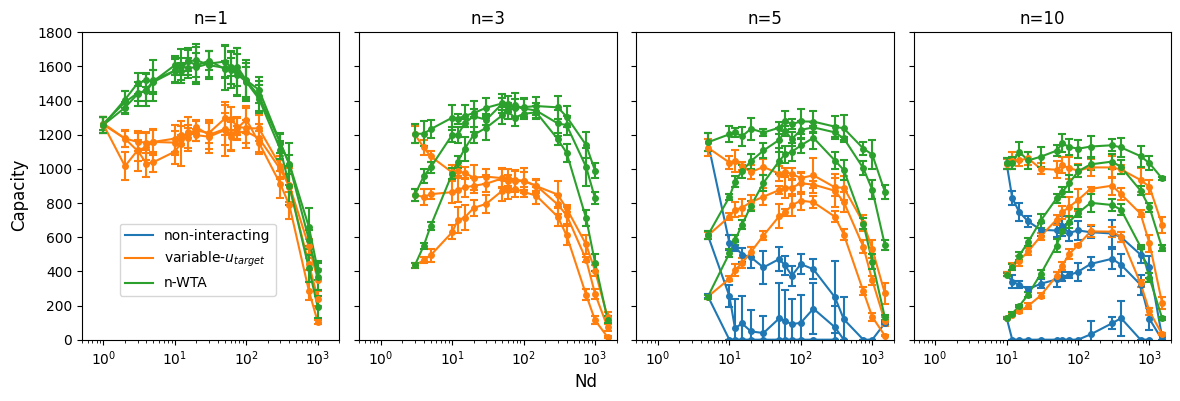

In [ ]:
n_panels = 4
n_rows = 1
n_cols = 4

dfs1 = [pd.read_csv(file_path) for file_path in files_path1]
dfs2 = [pd.read_csv(file_path) for file_path in files_path2]
dfs3 = [pd.read_csv(file_path) for file_path in files_path3]

dfs_list = [dfs1, dfs2, dfs3]

fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, figsize=(12, 4))

for ndR_idx, ndR_value in enumerate([1, 3, 5, 10]):
    ax_i = ndR_idx//n_cols
    ax_j = ndR_idx%n_cols
    for coeff_idx, coeff_str in enumerate(coeff_list):
        for dfs_idx, dfs in enumerate(dfs_list):
            if dfs_idx == 0:
                label_str = "non-interacting"
            elif dfs_idx == 1:
                label_str = r"variable-$u_{target}$"
            else:
                label_str = "n-WTA"
            try:
                df = dfs[coeff_idx]
                subset = df[df['ndR'] == ndR_value]
                subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
                subset = subset.sort_values("nd")
                max_nd = subset['nd'].max()
                min_nd = subset['nd'].min()
                nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
                try:
                    xs = np.log(subset['nd'].to_numpy())
                    ys = subset['capacity'].to_numpy()
                    y_sem = subset['sem'].to_numpy()
                    # spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
                    # fitted_capacity = spline(np.log(nd_plot_list))

                    # ax[ax_i, ax_j].plot(nd_plot_list, fitted_capacity, label=f"{coeff_str}", c=f"C{ndR_idx}")
                    if coeff_idx == 0:
                        ax[ax_j].plot(subset['nd'], subset['capacity'], label=f"{label_str}", c=f"C{dfs_idx}")    #  Original points line
                    else:
                        ax[ax_j].plot(subset['nd'], subset['capacity'], c=f"C{dfs_idx}")    #  Original points line
                except: pass

                ax[ax_j].errorbar(
                    x=subset['nd'],
                    y=subset['capacity'],
                    yerr=2.571*subset['sem'], 
                    fmt='o',  
                    markersize=4,
                    capsize=3,
                    capthick=1.5,
                    elinewidth=1.5, 
                    c=f"C{dfs_idx}"
                )
            except: pass

    ax[ax_j].set_xlim(0.5, 2000)
    ax[ax_j].set_ylim(0, 1800)
    # ax[ax_j].set_xlabel("Nd")
    # ax[ax_j].set_ylabel("capacity")
    ax[ax_j].set_xscale("log")
    ax[ax_j].set_title(f"n={ndR_value}") 
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.supxlabel("Nd")
fig.supylabel("Capacity")
# fig.suptitle("coeffs=[infty, 4, 1]", fontsize=16, y=1.05)
ax[3].legend(bbox_to_anchor=(-2.45, 0.4))


# plt.savefig("../figures/capa_vs_nd_4Panels.pdf")